# Datos Faltantes

In [3]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [5]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
135,-0.005515,-0.044642,0.056307,-0.036656,-0.048351,-0.042963,-0.072854,0.037999,0.050782,0.056912,272.0
111,0.019913,-0.044642,0.004572,-0.026328,0.023198,0.010273,0.067048,-0.039493,-0.023647,-0.046641,59.0
169,-0.001882,-0.044642,-0.026684,0.049415,0.058973,-0.016032,-0.047082,0.071210,0.133597,0.019633,152.0
83,-0.038207,-0.044642,0.009961,-0.046985,-0.059359,-0.052983,-0.010266,-0.039493,-0.015999,-0.042499,210.0
302,0.012648,-0.044642,0.033673,0.033337,0.030078,0.027183,-0.002903,0.008847,0.031193,0.027917,198.0
99,-0.001882,-0.044642,-0.064408,0.011544,0.027326,0.037517,-0.013948,0.034309,0.011785,-0.054925,83.0
409,-0.052738,0.050680,-0.011595,0.056301,0.056221,0.072902,-0.039719,0.071210,0.030564,-0.005220,181.0
109,0.038076,0.050680,-0.009439,0.002351,0.001183,0.037517,-0.054446,0.050176,-0.025953,0.106617,81.0
427,-0.034575,0.050680,0.005650,-0.005670,-0.073119,-0.062691,-0.006584,-0.039493,-0.045424,0.032059,67.0


In [6]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [7]:
#valores faltantes por columna
print(data.isnull().sum())

#total de valores faltantes: 88
print(data.isnull().sum().sum())
#filas con al menos un faltante (≤ 88)
print(data.isnull().any(axis=1).sum())    

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64
88
83


Valores faltantes: 88, que es la cantidad de valores (celdas) vacíos; bmi tiene 44 valores faltantes y bp tiene 44; las demás columnas no tienen.

Filas que tienen al menos un valor vacío: 83. Como 5 filas tienen NaN en bmi y en bp a la vez, 88 celdas vacías quedan repartidas en solo 83 filas (88 - 5 = 83).

En total son 88 valores en 83 filas.

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [ ]:
#Crear Copia para conservar el original con NaN
data_simple = data.copy()

imputer_media = SimpleImputer(strategy='mean')
data_simple[['bmi']] = imputer_media.fit_transform(data_simple[['bmi']])

#Verificar que ya no hay faltantes en bmi
print(data_simple['bmi'].isnull().sum())

0


Se utilizan dobles corchetes: [['bmi']] porque SimpleImputer espera un DataFrame o arreglo 2D, no una Serie.

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [8]:
#Imputación simple también para bp, para poder comparar
data_simple[['bp']] = SimpleImputer(strategy='mean').fit_transform(data_simple[['bp']])

#KNN: se usan todas las columnas numéricas para calcular los vecinos
data_knn = data.copy()
knn_imputer = KNNImputer(n_neighbors=5)
data_knn[:] = knn_imputer.fit_transform(data_knn)

#Comparación de estadísticos
comparacion = pd.DataFrame({
    'bmi_original': data['bmi'].describe(),
    'bmi_simple': data_simple['bmi'].describe(),
    'bmi_knn': data_knn['bmi'].describe(),
    'bp_original': data['bp'].describe(),
    'bp_simple': data_simple['bp'].describe(),
    'bp_knn': data_knn['bp'].describe(),
})
print(comparacion)

#Valores imputados en las filas que tenían NaN
filas_nan = data[data['bmi'].isnull()].index
print(pd.DataFrame({
    'simple': data_simple.loc[filas_nan, 'bmi'],
    'knn': data_knn.loc[filas_nan, 'bmi']
}).head(10))

       bmi_original  bmi_simple     bmi_knn  bp_original   bp_simple  \
count    398.000000  442.000000  442.000000   398.000000  442.000000   
mean      -0.000205   -0.000205    0.000060     0.000465    0.000465   
std        0.046989    0.044583    0.045621     0.048043    0.045583   
min       -0.089197   -0.089197   -0.089197    -0.112399   -0.112399   
25%       -0.035037   -0.030996   -0.033151    -0.033213   -0.033213   
50%       -0.007284   -0.000817   -0.006206    -0.005670    0.000465   
75%        0.030440    0.024781    0.030440     0.035644    0.028758   
max        0.160855    0.160855    0.160855     0.132044    0.132044   

           bp_knn  
count  442.000000  
mean     0.000292  
std      0.046398  
min     -0.112399  
25%     -0.033213  
50%     -0.005670  
75%      0.034391  
max      0.132044  
      simple       knn
9  -0.000205  0.072690
30 -0.000205  0.007806
39 -0.000205 -0.024529
55 -0.000205 -0.000601
70 -0.000205 -0.021511
72 -0.000205  0.010823
73 -0.0002

La imputación simple pone el mismo valor (la media) en todas las filas faltantes, así que reduce la desviación estándar (std).

KNN asigna valores distintos según los vecinos más parecidos, por lo que conserva mejor la variabilidad y la forma de la distribución.

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

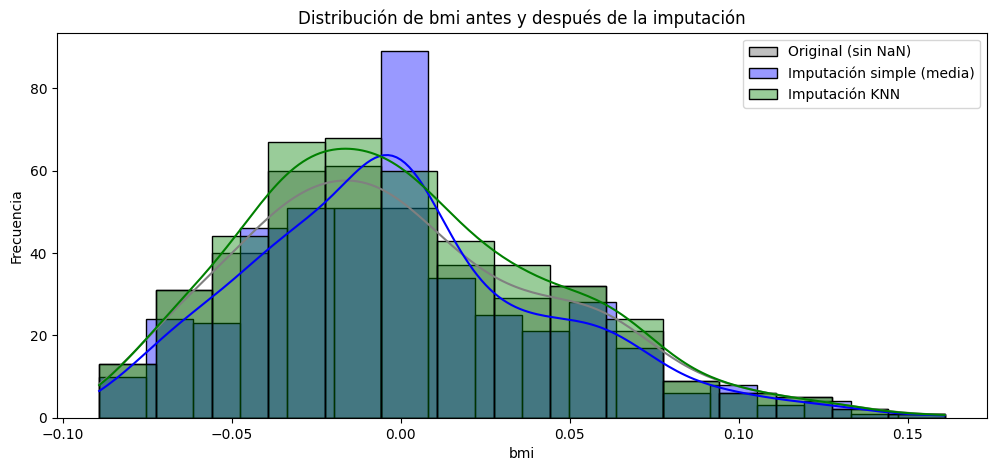

Desv. estándar original: 0.04698913634811231
Desv. estándar simple:   0.04458342423774498
Desv. estándar KNN:      0.04562075994865887


In [12]:
plt.figure(figsize=(12, 5))

sns.histplot(data['bmi'].dropna(), color='gray', label='Original (sin NaN)', kde=True, alpha=0.5)
sns.histplot(data_simple['bmi'], color='blue', label='Imputación simple (media)', kde=True, alpha=0.4)
sns.histplot(data_knn['bmi'], color='green', label='Imputación KNN', kde=True, alpha=0.4)

plt.title('Distribución de bmi antes y después de la imputación')
plt.xlabel('bmi')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

print("Desv. estándar original:", data['bmi'].std())
print("Desv. estándar simple:  ", data_simple['bmi'].std())
print("Desv. estándar KNN:     ", data_knn['bmi'].std())


En el histograma se aprecia un pico alto alrededor de la media en la versión con imputación simple (todos los NaN se acumulan en ese valor), mientras que la de KNN se parece más a la distribución original.

-Gris (original sin NaN): los 398 valores reales de bmi (442 menos los 44 faltantes). Es la referencia: la forma “verdadera” de la distribución. 

-Azul (imputación simple): los 398 valores reales más 44 valores copiados, todos iguales a la media. 

-Verde (imputación KNN): los 398 valores reales más 44 valores estimados a partir de los vecinos más parecidos. 

La imputación por media concentra los 44 valores faltantes en un solo punto, generando un pico artificial y reduciendo la varianza de bmi. La imputación KNN distribuye los valores imputados según la similitud entre observaciones, por lo que preserva mejor la forma original de la distribución. Por ello, KNN resulta más adecuada cuando se quiere conservar la estructura de los datos.

La desviación estándar de bmi fue de 0.0470 en los datos originales, 0.0446 con imputación por media y 0.0456 con KNN. Esto confirma que la imputación simple reduce más la varianza que KNN, el cual preserva mejor la dispersión original, aunque también la reduce ligeramente al promediar a los vecinos.
